### 1(a)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

data_dir = Path("data")
train = pd.read_csv(data_dir / "aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv(data_dir / "aps_failure_test_set.csv", skiprows=20, na_values="na")

X = train.drop(columns="class")
T = test[X.columns]
y = train["class"].eq("pos").to_numpy(dtype=int)
yt = test["class"].eq("pos").to_numpy(dtype=int)
print("Training and test dimensions:", train.shape, test.shape)

Training and test dimensions: (60000, 171) (16000, 171)


### 1(b)(i)

Common approaches include filling each feature with its mean or median, borrowing values from similar observations, and predicting missing entries from other features. I use each feature’s training median because extreme readings can strongly affect the mean. The same medians apply to held-out trucks. During cross-validation, each fold supplies its own training medians. [Scikit-learn imputation guide](https://scikit-learn.org/stable/modules/impute.html)

In [2]:
medians = X.median()
A = X.fillna(medians)
B = T.fillna(medians)
assert A.notna().all().all() and B.notna().all().all()

### 1(b)(ii)

In [3]:
means = A.mean()
cv = A.std(ddof=1).div(means.where(means.ne(0))).rename("CV")
print(cv.to_string(na_rep="undefined (zero mean)"))

aa_000      2.450938
ab_000     10.383494
ac_000      2.310241
ad_000    244.322816
ae_000     24.200137
af_000     19.471295
ag_000     92.917755
ag_001     35.249314
ag_002     17.565907
ag_003      8.647402
ag_004      5.463067
ag_005      2.956239
ag_006      2.356948
ag_007      2.858954
ag_008      6.221477
ag_009     33.357567
ah_000      2.311735
ai_000     18.203806
aj_000     44.265996
ak_000     80.424975
al_000      9.173106
am_0        9.155221
an_000      2.249995
ao_000      2.270678
ap_000      3.081120
aq_000      2.856931
ar_000     11.354347
as_000     87.332500
at_000     23.708187
au_000     68.882751
av_000      6.005834
ax_000      4.019051
ay_000     37.428285
ay_001     52.824714
ay_002     39.248654
ay_003     28.735090
ay_004     33.752345
ay_005     12.524655
ay_006      3.053210
ay_007      3.313956
ay_008      3.815682
ay_009     84.733735
az_000      9.405736
az_001      7.720873
az_002     13.271741
az_003      7.527395
az_004      2.848992
az_005      3

### 1(b)(iii)

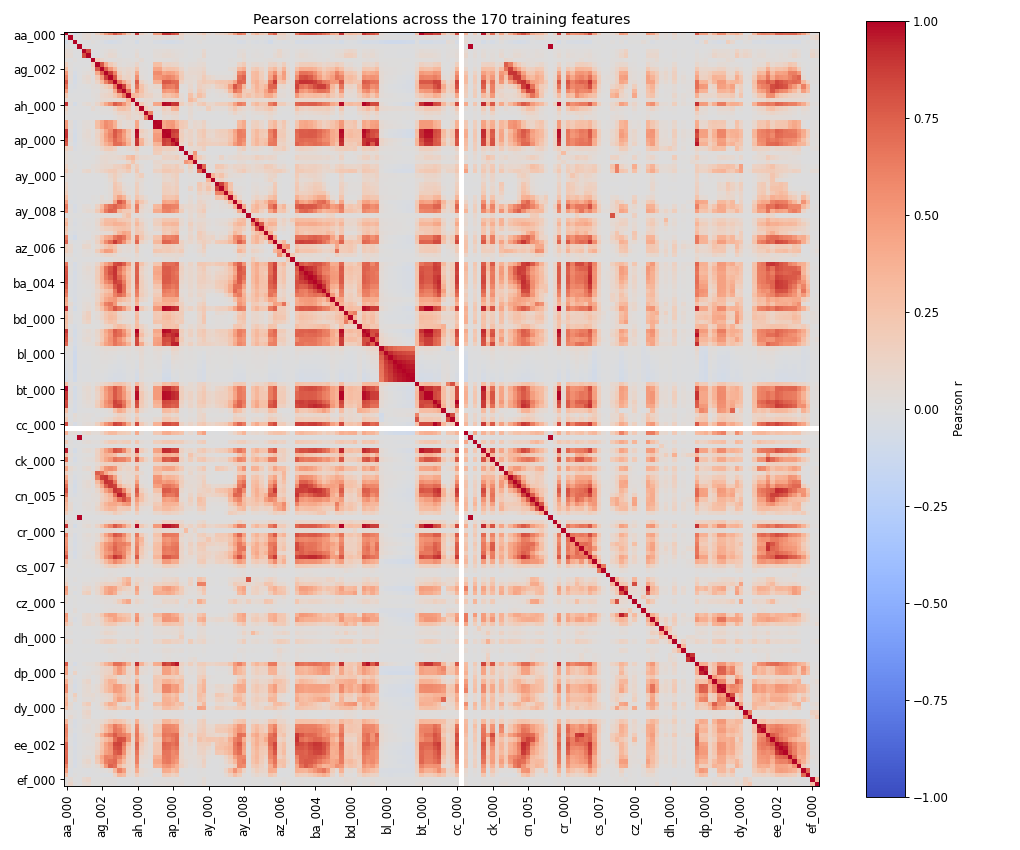

In [4]:
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(A.corr(), cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest")
ticks = np.arange(0, A.shape[1], 8)
ax.set_xticks(ticks, A.columns[ticks], rotation=90)
ax.set_yticks(ticks, A.columns[ticks])
ax.set_title("Pearson correlations across the 170 training features")
fig.colorbar(im, ax=ax, label="Pearson r")
plt.tight_layout()
plt.show()

### 1(b)(iv)

The scatter plots show whether pairs of features appear to separate the classes. A large coefficient of variation measures spread relative to the mean. A few extreme readings can therefore rank a feature highly. Neither the ranking nor visual separation establishes statistical significance or a feature’s independent contribution after accounting for correlated predictors.

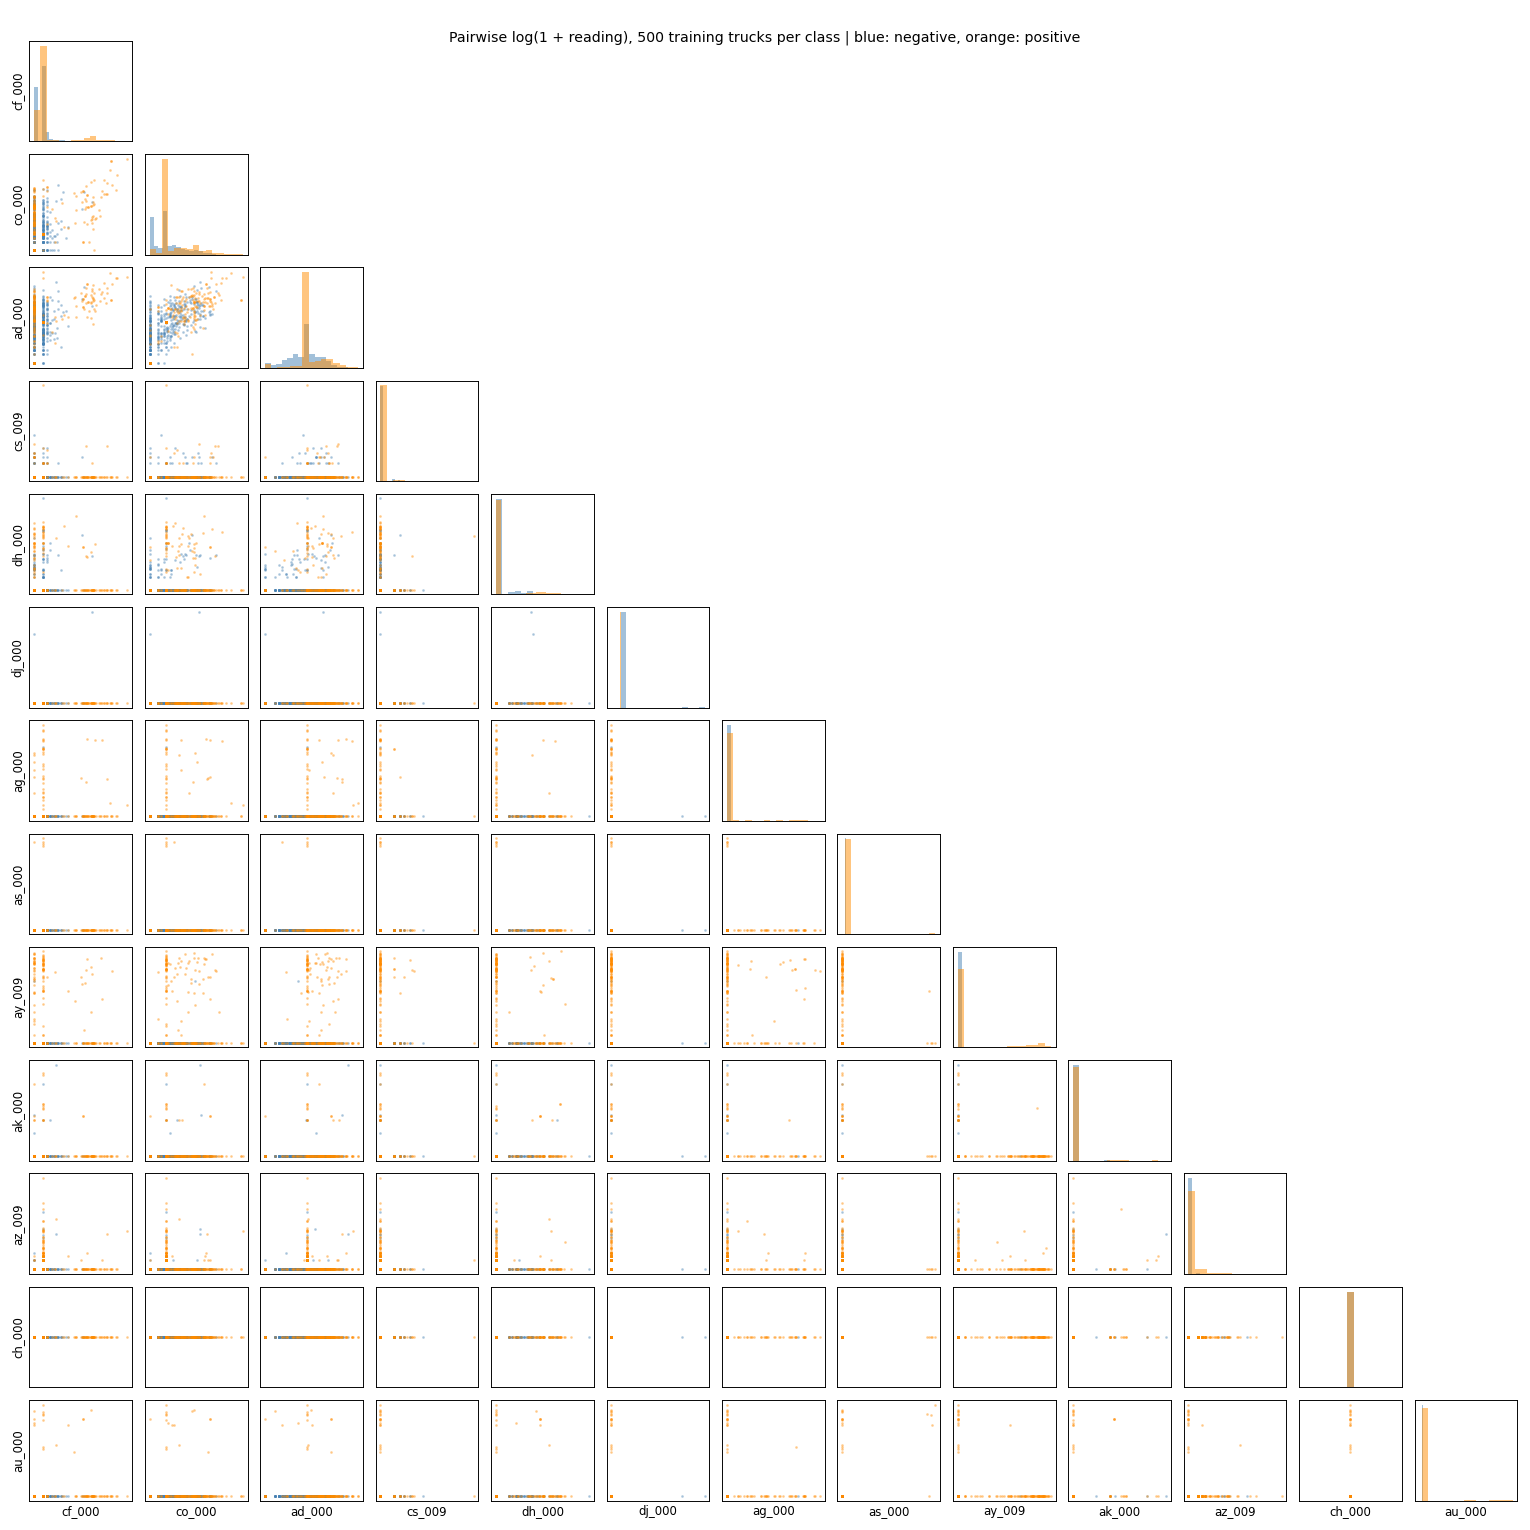

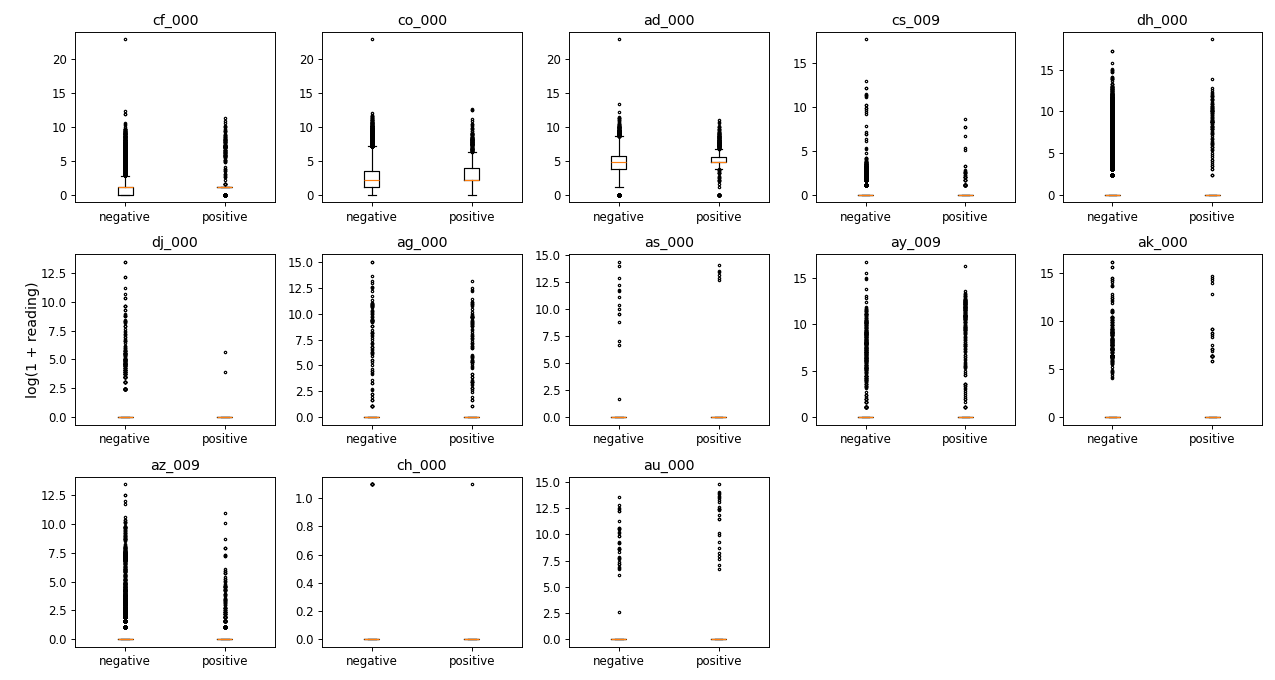

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751


In [5]:
top = cv.nlargest(int(np.sqrt(len(cv)))).index
print(cv.loc[top].to_string())
rng = np.random.default_rng(552)
fig, axes = plt.subplots(len(top), len(top), figsize=(18, 18))
for label, color in [(0, "steelblue"), (1, "darkorange")]:
    rows = rng.choice(np.flatnonzero(y == label), 500, replace=False)
    values = np.log1p(A.loc[rows, top].to_numpy())
    for i, name in enumerate(top):
        for j in range(i + 1):
            ax = axes[i, j]
            if i == j:
                ax.hist(values[:, j], bins=15, color=color, alpha=.5)
            else:
                ax.scatter(values[:, j], values[:, i], s=2, alpha=.3, color=color)
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(name)
            if i == len(top) - 1:
                ax.set_xlabel(top[j])
for i, j in zip(*np.triu_indices(len(top), 1)):
    axes[i, j].axis("off")
fig.suptitle("Pairwise log(1 + reading), 500 training trucks per class | blue: negative, orange: positive")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for ax, name in zip(axes.flat, top):
    ax.boxplot([np.log1p(A.loc[y == k, name]) for k in (0, 1)], flierprops={"markersize": 2})
    ax.set_xticks([1, 2], ["negative", "positive"])
    ax.set_title(name)
for ax in list(axes.flat)[len(top):]:
    ax.axis("off")
fig.supylabel("log(1 + reading)")
fig.tight_layout()
plt.show()

### 1(b)(v)

The training set contains 59,000 negative and 1,000 positive trucks. The test set contains 15,625 negative and 375 positive trucks. The 59-to-1 training imbalance means a classifier that always predicts negative achieves 98.33% training accuracy while missing every failure.

In [6]:
print(pd.DataFrame({"Training": train["class"].value_counts(), "Test": test["class"].value_counts()}))

       Training   Test
class                 
neg       59000  15625
pos        1000    375


### 1(c)

The unweighted forest's out-of-bag error was 0.61%, compared with 0.77% on the test set.

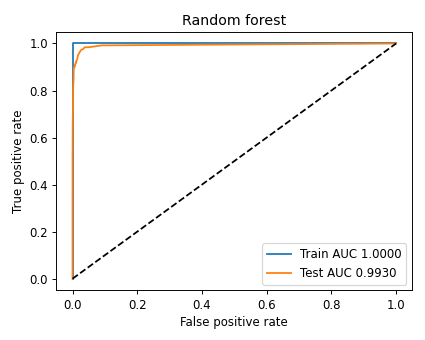

                          TN    FP     FN      TP     Error      AUC
Random forest Train  59000.0   0.0    0.0  1000.0  0.000000  1.00000
              Test   15605.0  20.0  103.0   272.0  0.007687  0.99304
OOB error: 0.006149999999999989


In [7]:
results = {}

def evaluate(name, train_scores, test_scores):
    fig, ax = plt.subplots(figsize=(5, 4))
    for split, labels, scores in [("Train", y, train_scores), ("Test", yt, test_scores)]:
        tn, fp, fn, tp = confusion_matrix(labels, scores >= .5, labels=[0, 1]).ravel()
        auc = roc_auc_score(labels, scores)
        results[name, split] = dict(TN=tn, FP=fp, FN=fn, TP=tp, Error=(fp+fn)/len(labels), AUC=auc)
        fpr, tpr, _ = roc_curve(labels, scores)
        ax.plot(fpr, tpr, label=f"{split} AUC {auc:.4f}")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title=name)
    ax.legend()
    plt.tight_layout()
    plt.show()
    print(pd.DataFrame(results).T.to_string())

def fit_forest(name, weights):
    model = RandomForestClassifier(n_estimators=100, class_weight=weights, oob_score=True,
                                   n_jobs=4, random_state=552)
    model.fit(A, y)
    evaluate(name, model.predict_proba(A)[:, 1], model.predict_proba(B)[:, 1])
    print("OOB error:", 1 - model.oob_score_)
    return 1 - model.oob_score_

oob = fit_forest("Random forest", None)

### 1(d)

A forest can give rare failures greater weight when choosing splits or balance the class counts in each tree’s bootstrap sample. Here each tree weights classes inversely to their frequencies in its bootstrap sample. [Random forest class weights](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

Weighting changed the OOB error to 0.79%. On the test set, missed failures changed from 103 to 159, false alarms from 20 to 19, and overall error from 0.77% to 1.11%.

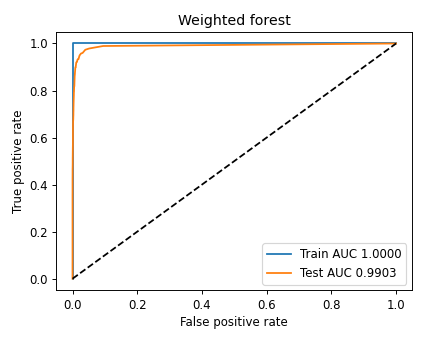

                            TN    FP     FN      TP     Error       AUC
Random forest   Train  59000.0   0.0    0.0  1000.0  0.000000  1.000000
                Test   15605.0  20.0  103.0   272.0  0.007687  0.993040
Weighted forest Train  59000.0   0.0    0.0  1000.0  0.000000  1.000000
                Test   15606.0  19.0  159.0   216.0  0.011125  0.990344
OOB error: 0.007900000000000018


In [8]:
weighted_oob = fit_forest("Weighted forest", "balanced_subsample")

### 1(e)

Five-fold cross-validation selected $\alpha=0.0001$. The cross-validation error was 1.67%, compared with a test error of 2.34%. The model classified every test truck as negative, missing all 375 failures. Its test AUC was 0.5000.

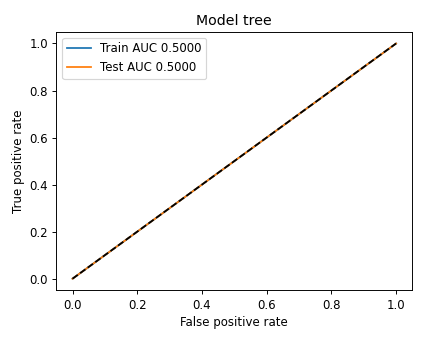

0.0001    0.016667
0.0010    0.016667
0.0100    0.016667
                            TN    FP      FN      TP     Error       AUC
Random forest   Train  59000.0   0.0     0.0  1000.0  0.000000  1.000000
                Test   15605.0  20.0   103.0   272.0  0.007687  0.993040
Weighted forest Train  59000.0   0.0     0.0  1000.0  0.000000  1.000000
                Test   15606.0  19.0   159.0   216.0  0.011125  0.990344
Model tree      Train  59000.0   0.0  1000.0     0.0  0.016667  0.500000
                Test   15625.0   0.0   375.0     0.0  0.023438  0.500000
Selected alpha: 0.0001


In [9]:
def prepare(train_x, valid_x):
    median = train_x.median()
    a = np.log1p(train_x.fillna(median).to_numpy(dtype=np.float32))
    b = np.log1p(valid_x.fillna(median).to_numpy(dtype=np.float32))
    scaler = StandardScaler()
    return scaler.fit_transform(a), scaler.transform(b)

def fit_tree(a, labels, alpha):
    def logistic(x, target):
        model = XGBClassifier(booster="gblinear", objective="binary:logistic", reg_alpha=alpha,
                              reg_lambda=0, updater="coord_descent", n_estimators=30,
                              learning_rate=.3, n_jobs=4, random_state=552)
        return model.fit(x, target)
    root = logistic(a, labels)
    scores = root.predict_proba(a)[:, 1]
    threshold = np.quantile(scores, .9)
    right = scores > threshold
    leaves = {}
    for side in (False, True):
        mask = right == side
        if np.unique(labels[mask]).size == 2:
            leaves[side] = logistic(a[mask], labels[mask])
        elif mask.any():
            leaves[side] = float(labels[mask][0])
    def predict(x):
        scores = root.predict_proba(x)[:, 1]
        right = scores > threshold
        for side, leaf in leaves.items():
            mask = right == side
            if mask.any():
                scores[mask] = leaf if isinstance(leaf, float) else leaf.predict_proba(x[mask])[:, 1]
        return scores
    return predict

def experiment(name, resample=None):
    penalties = [0.0001, 0.001, 0.01]
    errors = []
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
    for fitting, validation in folds.split(X, y):
        a, b = prepare(X.iloc[fitting], X.iloc[validation])
        labels = y[fitting]
        if resample is not None:
            a, labels = resample(a, labels)
        errors.append([np.mean((fit_tree(a, labels, alpha)(b) >= .5) != y[validation])
                       for alpha in penalties])
    table = pd.DataFrame(errors, columns=penalties)
    summary = table.mean().rename("Mean validation error")
    print(summary.to_string())
    alpha = summary.idxmin()
    a, b = prepare(X, T)
    fitting, labels = (a, y) if resample is None else resample(a, y)
    predict = fit_tree(fitting, labels, alpha)
    evaluate(name, predict(a), predict(b))
    print("Selected alpha:", alpha)
    return alpha, summary.loc[alpha]

alpha_raw, cv_raw = experiment("Model tree")

### 1(f)

SMOTE was applied only to the training portion of each fold. Five-fold cross-validation selected $\alpha=0.0001$, with a validation error of 4.33% and a test error of 4.31%. Compared with 1(e), SMOTE reduced missed failures from 375 to 16 and increased test AUC from 0.5000 to 0.9905. False alarms rose from 0 to 673, increasing the overall test error from 2.34% to 4.31%.

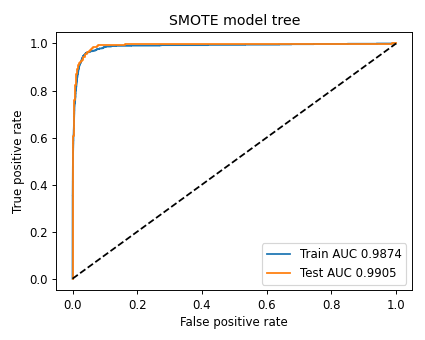

0.0001    0.043283
0.0010    0.044617
0.0100    0.050617
                             TN      FP      FN      TP     Error       AUC
Random forest    Train  59000.0     0.0     0.0  1000.0  0.000000  1.000000
                 Test   15605.0    20.0   103.0   272.0  0.007687  0.993040
Weighted forest  Train  59000.0     0.0     0.0  1000.0  0.000000  1.000000
                 Test   15606.0    19.0   159.0   216.0  0.011125  0.990344
Model tree       Train  59000.0     0.0  1000.0     0.0  0.016667  0.500000
                 Test   15625.0     0.0   375.0     0.0  0.023438  0.500000
SMOTE model tree Train  56473.0  2527.0    40.0   960.0  0.042783  0.987362
                 Test   14952.0   673.0    16.0   359.0  0.043062  0.990476
Selected alpha: 0.0001


In [10]:
def smote(a, labels):
    rng = np.random.default_rng(552)
    positive = a[labels == 1]
    count = np.sum(labels == 0) - len(positive)
    neighbors = NearestNeighbors(n_neighbors=5).fit(positive).kneighbors(return_distance=False)
    base = rng.integers(len(positive), size=count)
    other = neighbors[base, rng.integers(5, size=count)]
    fraction = rng.random((count, 1), dtype=np.float32)
    synthetic = positive[base] + fraction * (positive[other] - positive[base])
    return np.vstack([a, synthetic]), np.concatenate([labels, np.ones(count, dtype=int)])

alpha_smote, cv_smote = experiment("SMOTE model tree", smote)

## Question 2 (ISLR 6.6.3)

**(a) iv.** Training RSS decreases or stays constant as $s$ increases. A larger $s$ allows every coefficient vector that was feasible at a smaller $s$, so the minimum RSS can only improve or stay the same. It levels off once a least-squares solution is feasible.

**(b) ii.** Expected test RSS typically decreases at first and then increases. At $s=0$, the model predicts the training mean for every observation. Increasing $s$ initially reduces bias by allowing the predictors to contribute. As the constraint becomes weaker, increased variance can outweigh the reduction in bias and raise test RSS.

**(c) iii.** Variance generally increases. With less shrinkage, the fitted coefficients and predictions become more sensitive to the particular training sample.

**(d) iv.** Squared bias generally decreases. A larger $s$ lets the fitted slopes move away from zero and capture more of the relationship between the predictors and the response.

**(e) v.** Irreducible error remains constant. It comes from the variability of the response at a given predictor value and is independent of $s$.

## Question 3 (ISLR 6.6.5)

**(a)** Let $x=x_{11}=x_{12}$ and $y=y_1$. Since the data are centered, $x_{21}=x_{22}=-x$, $y_2=-y$, and the fitted intercept is zero. The two residuals have opposite signs and the same magnitude. The ridge optimization problem is therefore

$$
\min_{\beta_1,\beta_2}
\;2\big[y-x(\beta_1+\beta_2)\big]^2
+\lambda(\beta_1^2+\beta_2^2).
$$

**(b)** Let $t=\beta_1+\beta_2$. For fixed $t$, every coefficient pair gives the same fitted values and RSS. The ridge penalty satisfies

$$
\beta_1^2+\beta_2^2
=\frac{t^2}{2}+\frac{(\beta_1-\beta_2)^2}{2}.
$$

For $\lambda>0$, the penalty is smallest when the second term is zero. Thus $\hat\beta_1=\hat\beta_2$.

**(c)** The lasso optimization problem is

$$
\min_{\beta_1,\beta_2}
\;2\big[y-x(\beta_1+\beta_2)\big]^2
+\lambda\big(|\beta_1|+|\beta_2|\big).
$$

**(d)** For a fixed sum $t$, the triangle inequality gives $|\beta_1|+|\beta_2|\geq |t|$. Every split of $t$ into two nonnegative coefficients or two nonpositive coefficients attains equality. Let $\hat t$ minimize $2(y-xt)^2+\lambda|t|$. For $\lambda>0$, the full set of lasso solutions is

$$
(\hat\beta_1,\hat\beta_2)
=\big(a\hat t,(1-a)\hat t\big), \qquad 0\leq a\leq 1.
$$

If $\hat t\neq 0$, this gives infinitely many solutions, all with the same RSS and penalty. For example, $(\hat t,0)$ and $(0,\hat t)$ are equally good fits. If $\hat t=0$, the unique solution is $(0,0)$.

## Question 4 (ISLR 8.4.5)

**Majority vote predicts Red.** Six trees assign Red a probability greater than $0.5$, and four assign Red a probability less than $0.5$. Red wins the vote 6 to 4.

**Average probability predicts Green.** The average estimated probability of Red is

$$
\frac{0.10+0.15+0.20+0.20+0.55+0.60+0.60+0.65+0.70+0.75}{10}
=\frac{4.50}{10}=0.45.
$$

The average estimated probability of Green is $1-0.45=0.55$, so Green has the higher probability. The methods give different predictions because majority voting counts each tree's winning class, while averaging also accounts for how strongly each tree favors that class.